<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan2/BTVN/MachineLearningT2_BTVN_Bai2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kich thuoc du lieu: (1797, 64)
So lop: 10
Gia tri thieu: 0


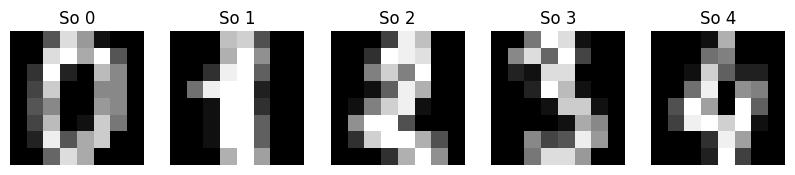


MO HINH: KNN k=5
Accuracy: 0.9638888888888889
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.92      1.00      0.96        36
           2       0.95      1.00      0.97        35
           3       1.00      0.97      0.99        37
           4       0.97      0.94      0.96        36
           5       0.97      0.97      0.97        37
           6       0.97      1.00      0.99        36
           7       0.92      0.97      0.95        36
           8       0.97      0.89      0.93        35
           9       0.97      0.89      0.93        36

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360


MO HINH: SVM poly
Accuracy: 0.9722222222222222
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.97      0.97    

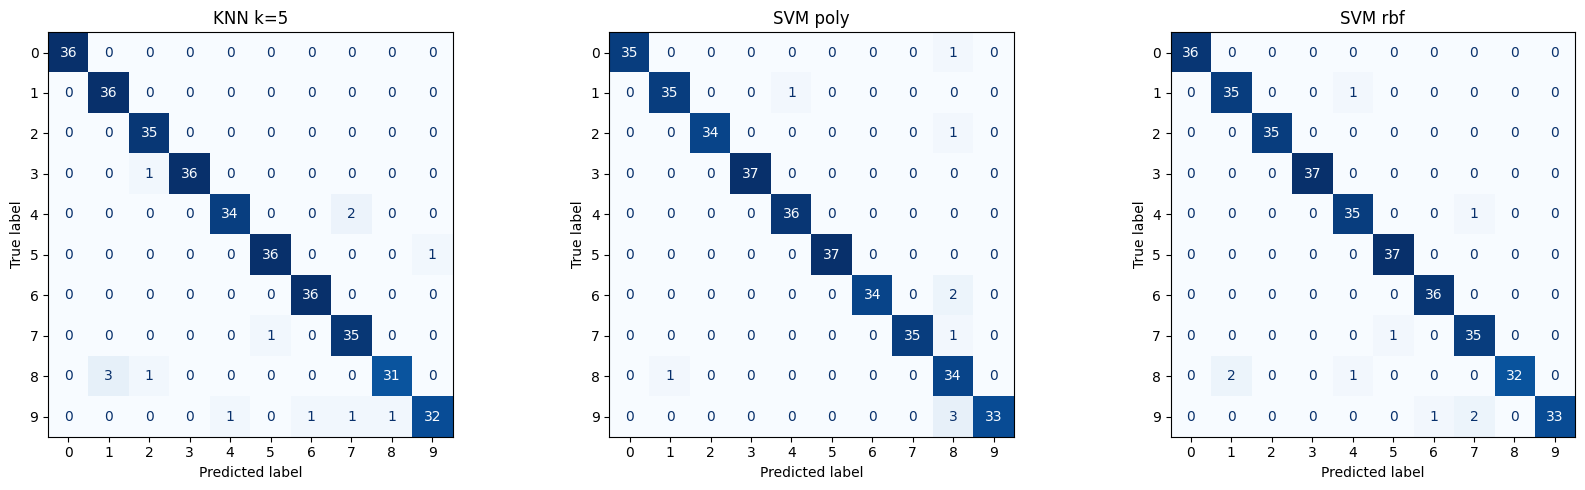


BANG SO SANH:
 Mo hinh  Accuracy
 KNN k=5  0.963889
SVM poly  0.972222
 SVM rbf  0.975000


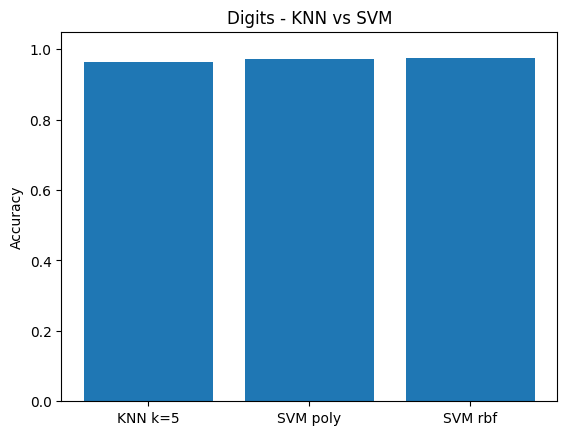


Mo hinh co Accuracy cao nhat:
Mo hinh     SVM rbf
Accuracy      0.975
Name: 2, dtype: object


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Nap bo du lieu chu so
digits = load_digits()

X = digits.data
y = digits.target

print("Kich thuoc du lieu:", X.shape)
print("So lop:", len(np.unique(y)))
print("Gia tri thieu:", pd.DataFrame(X).isna().sum().sum())

# 2. Hien thi 5 chu so mau
fig, axes = plt.subplots(1, 5, figsize=(10, 2))

for ax, i in zip(axes, range(5)):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"So {y[i]}")
    ax.axis("off")

plt.show()

# 3. Chia 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Tao 3 mo hinh
models = {
    "KNN k=5": Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM poly": Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(kernel="poly", C=1, gamma="scale"))
    ]),
    "SVM rbf": Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(kernel="rbf", C=1, gamma="scale"))
    ])
}

# 5. Huan luyen va danh gia
results = []
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, pred)

    results.append({
        "Mo hinh": name,
        "Accuracy": accuracy
    })

    print("\nMO HINH:", name)
    print("Accuracy:", accuracy)
    print(classification_report(
        y_test, pred, zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        ax=ax,
        cmap="Blues",
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

# 6. Bang so sanh
df = pd.DataFrame(results)

print("\nBANG SO SANH:")
print(df.to_string(index=False))

# 7. Bieu do
plt.bar(df["Mo hinh"], df["Accuracy"])
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("Digits - KNN vs SVM")
plt.show()

print("\nMo hinh co Accuracy cao nhat:")
print(df.loc[df["Accuracy"].idxmax()])
